# Banana shelf-life: model comparison for the paper revision (Reviewers 3 and 5)
**Run: Runtime -> Change runtime type -> T4 GPU, then Run all.** Approve the Google Drive popup once. Takes roughly 10-20 minutes.

**What this notebook does**
- Compares **MobileNetV2, ResNet-18, EfficientNet-B0 and ShuffleNetV2** on MAE, RMSE and R2, plus size, MACs and latency.
- Uses the **same split as the paper** (seed 42, stratified by day: train 456 / val 57 / test 58). The notebook stops if the split or the published model's numbers do not match the paper.
- All four are trained identically: frozen ImageNet backbone, 128x128 input, head = pooled features -> Dense(64, ReLU) -> Dropout(0.3) -> Linear(1), weighted MSE, Adam 1e-3, batch 16, 20 epochs, final weights (no model selection), 5 seeds.
- **Why cached features:** the backbones are frozen, so features are computed once per backbone and only the small head is trained. Same maths, minutes instead of hours.
- Reports **test** metrics as the main result, with validation alongside (Table 5 in the paper used validation).

**Parts:** A = EDA (run once) | B = error analysis (one section per model) | C = final comparison (one table, two figures).
**Outputs** go to `banana_project/revision/results/` (CSVs) and `.../results/figures/` (300 dpi PNGs). The notebook is resumable: a model already in the CSVs is skipped.

In [2]:
# 1) Setup: imports, protocol constants, Google Drive, GPU check
import os, sys, time, json, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import tensorflow as tf
tf.config.set_visible_devices([], 'GPU')   # TF only decodes images and runs the published Keras model; keep the GPU free for PyTorch
import torch, torch.nn as nn, torchvision
from torchvision import models as tvm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats
warnings.filterwarnings('ignore', category=FutureWarning)

from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/banana_project'
RES = os.path.join(BASE, 'revision', 'results')
FIG = os.path.join(RES, 'figures')
CACHE = os.path.join(BASE, 'revision', 'cache')
for d in (RES, FIG, CACHE): os.makedirs(d, exist_ok=True)

# Protocol: identical for every model
IMG_SIZE, BATCH, EPOCHS, LR, HIDDEN, DROPOUT = 128, 16, 20, 1e-3, 64, 0.3
SEEDS = [0, 1, 2, 3, 4]
RESUME = True      # skip models already complete in the result CSVs
MODELS = ['MobileNetV2', 'ResNet-18', 'EfficientNet-B0', 'ShuffleNetV2']
PUB = 'MobileNetV2 (Keras, published)'
COLORS = {'MobileNetV2': '#1f77b4', 'ResNet-18': '#d62728', 'EfficientNet-B0': '#2ca02c', 'ShuffleNetV2': '#ff7f0e', PUB: '#7f7f7f'}
SLUG = {'MobileNetV2': 'mobilenetv2', 'ResNet-18': 'resnet18', 'EfficientNet-B0': 'efficientnetb0', 'ShuffleNetV2': 'shufflenetv2'}
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None
if DEVICE != 'cuda':
    print('WARNING: no GPU. Set Runtime -> Change runtime type -> T4 GPU. GPU latency will be missing.')
CPU_NAME = next((l.split(':')[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name')), platform.processor())
run_info = dict(date=time.strftime('%Y-%m-%d %H:%M:%S'), torch=torch.__version__, torchvision=torchvision.__version__,
                tensorflow=tf.__version__, python=sys.version.split()[0], gpu=GPU_NAME, cpu=CPU_NAME,
                seeds=SEEDS, img_size=IMG_SIZE, batch=BATCH, epochs=EPOCHS, lr=LR, hidden=HIDDEN, dropout=DROPOUT)
json.dump(run_info, open(os.path.join(RES, 'run_info.json'), 'w'), indent=2)
print(run_info)

Mounted at /content/drive
{'date': '2026-11-21 03:28:36', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'tensorflow': '2.21.0', 'python': '3.13.16', 'gpu': 'Tesla T4', 'cpu': 'Intel(R) Xeon(R) CPU @ 2.00GHz', 'seeds': [0, 1, 2, 3, 4], 'img_size': 128, 'batch': 16, 'epochs': 20, 'lr': 0.001, 'hidden': 64, 'dropout': 0.3}


In [3]:
# 2) Data + split: same code as banana_model_evaluation.ipynb, then hard checks against the paper
df = pd.read_csv(os.path.join(BASE, 'manifest.csv'))
df['filepath'] = df.apply(lambda r: os.path.join(BASE, f"Day{r['day']}", os.path.basename(r['filepath'])), axis=1)
assert df['filepath'].map(os.path.exists).all(), 'Some image paths are missing'

train_df, temp_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df['day'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['day'])
df['split'] = 'train'; df.loc[val_df.index, 'split'] = 'val'; df.loc[test_df.index, 'split'] = 'test'
counts = df['split'].value_counts().to_dict()
print(counts)
assert counts == {'train': 456, 'val': 57, 'test': 58}, f'Split sizes differ from the paper: {counts}'

# The evaluation notebook saved its split next to its predictions: every row must agree (same order, same split)
ref = pd.read_csv(os.path.join(BASE, 'eval', 'predictions.csv'))
assert len(ref) == len(df)
assert (ref['file'].values == df['filepath'].map(os.path.basename).values).all(), 'File order differs from eval/predictions.csv'
assert (ref['day'].values == df['day'].values).all() and (ref['split'].values == df['split'].values).all(), 'Split differs from eval/predictions.csv'
print('Split matches the paper: 456/57/58 and identical to eval/predictions.csv')

# Load images exactly like the paper: decode -> bilinear resize to 128x128 (float 0-255). Normalisation is applied per backbone later.
def load(fp):
    img = tf.io.decode_jpeg(tf.io.read_file(fp), channels=3)
    return tf.image.resize(img, [IMG_SIZE, IMG_SIZE]).numpy()
fnames = df['filepath'].map(os.path.basename).values
xpath = os.path.join(CACHE, f'Xraw_{IMG_SIZE}.npz')      # resized images cached on Drive: the first read of 571 photos is slow (~6 min), reruns take seconds
Xraw = None
if RESUME and os.path.exists(xpath):
    z = np.load(xpath)
    if z['files'].shape == fnames.shape and (z['files'] == fnames).all() and z['X'].shape[1] == IMG_SIZE:
        Xraw = z['X']; print('Loaded resized images from cache')
if Xraw is None:
    Xraw = np.stack([load(fp) for fp in df['filepath']]).astype('float32')
    np.savez(xpath, X=Xraw, files=fnames)
y = df['day'].values.astype('float32')
days = df['day'].values
MASK = {s: (df['split'] == s).values for s in ['train', 'val', 'test']}
print('Images:', Xraw.shape, '| value range', Xraw.min(), Xraw.max())

{'train': 456, 'test': 58, 'val': 57}
Split matches the paper: 456/57/58 and identical to eval/predictions.csv
Images: (571, 128, 128, 3) | value range 0.0 255.0


In [4]:
# 3) Shared helpers: metrics, CSV I/O, sample weights, the regression head and its training loop
def reg_metrics(t, p):
    mse = mean_squared_error(t, p)
    return dict(n=int(len(t)), MAE=float(mean_absolute_error(t, p)), MSE=float(mse), RMSE=float(np.sqrt(mse)), R2=float(r2_score(t, p)))

def save_csv(d, name): d.to_csv(os.path.join(RES, name), index=False)
def load_csv(name):
    p = os.path.join(RES, name)
    if not os.path.exists(p): return None
    d = pd.read_csv(p)
    if 'seed' in d: d['seed'] = d['seed'].astype(str)
    return d
def upsert(name, new, model):
    old = load_csv(name)
    if old is not None: new = pd.concat([old[old['model'] != model], new], ignore_index=True)
    save_csv(new, name)
def savefig(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=300, bbox_inches='tight'); plt.show(); plt.close(fig)

# Inverse-frequency weights per day, normalised to mean 1.0 (same as the paper's training notebook)
def day_weights(d):
    cnt = pd.Series(d).value_counts()
    w = pd.Series(d).map(lambda k: 1.0 / cnt[k]).values.astype('float32')
    return (w * len(w) / w.sum()).astype('float32')

# Head = Dense(64, ReLU) -> Dropout(0.3) -> Linear(1). Glorot init + zero bias and Adam eps=1e-7 mimic Keras defaults.
class Head(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, HIDDEN), nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(HIDDEN, 1))
        for m in self.net:
            if isinstance(m, nn.Linear): nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x): return self.net(x).squeeze(-1)

def train_head(Ftr, ytr, wtr, seed, Fval=None, yval=None):
    # Fixed 20 epochs, final weights, no selection on val. Loss = mean(w * squared error), like Keras sample_weight.
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    head = Head(Ftr.shape[1]); opt = torch.optim.Adam(head.parameters(), lr=LR, eps=1e-7)
    Ft, yt, wt = torch.as_tensor(Ftr), torch.as_tensor(ytr), torch.as_tensor(wtr)
    curve = []
    for ep in range(EPOCHS):
        head.train(); perm = torch.randperm(len(Ft), generator=g); run = 0.0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            loss = (wt[idx] * (head(Ft[idx]) - yt[idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step(); run += loss.item() * len(idx)
        rec = dict(epoch=ep + 1, train_loss=run / len(perm))
        if Fval is not None:
            head.eval()
            with torch.no_grad(): rec['val_loss'] = float(((head(torch.as_tensor(Fval)) - torch.as_tensor(yval)) ** 2).mean())
        curve.append(rec)
    head.eval()
    return head, curve

def predict(head, F):
    with torch.no_grad(): return head(torch.as_tensor(F)).numpy()

def pred_rows(name, seed, p):
    return pd.DataFrame(dict(model=name, seed=str(seed), row=np.arange(len(df)), file=df['filepath'].map(os.path.basename).values,
                             day=days, split=df['split'].values, pred=np.asarray(p, dtype='float64')))
print('helpers ready')

helpers ready


# Part A. Exploratory data analysis (run once, shared by all models)
Questions: how are the images spread over days and splits, what do the photos look like, and how do colour and darkness change with ripening? The brightness and dark-pixel curves matter for the hypothesis that the model leans on overall brightness more than on spot density.

day,1,2,3,4,5,6,7,8,9,10
split,,,,,,,,,,
train,30,90,48,70,42,34,27,40,39,36
val,4,11,6,8,5,4,4,5,5,5
test,4,12,6,9,5,5,3,5,5,4
total,38,113,60,87,52,43,34,50,49,45


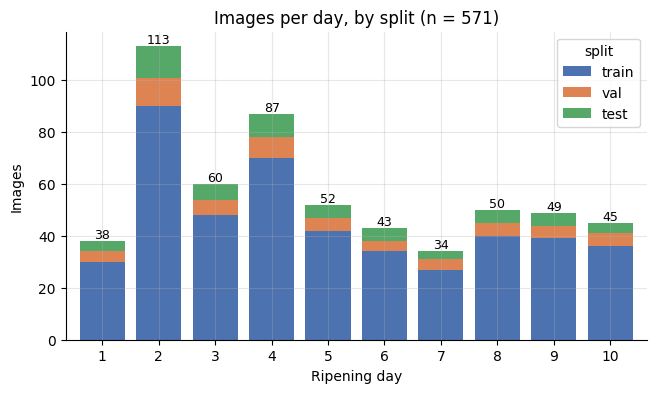

In [5]:
# A1) Images per day and how each day is divided between train / val / test
tab = df.groupby(['day', 'split']).size().unstack(fill_value=0)[['train', 'val', 'test']]
tab['total'] = tab.sum(axis=1)
display(tab.T)
tab.reset_index().to_csv(os.path.join(RES, 'eda_images_per_day.csv'), index=False)
fig, ax = plt.subplots(figsize=(7.5, 4))
tab[['train', 'val', 'test']].plot(kind='bar', stacked=True, ax=ax, color=['#4c72b0', '#dd8452', '#55a868'], width=.8)
for i, t in enumerate(tab['total']): ax.text(i, t + 1, str(t), ha='center', fontsize=9)
ax.set_xlabel('Ripening day'); ax.set_ylabel('Images'); ax.set_title('Images per day, by split (n = 571)'); ax.set_xticklabels(tab.index, rotation=0)
savefig(fig, 'eda_images_per_day.png')

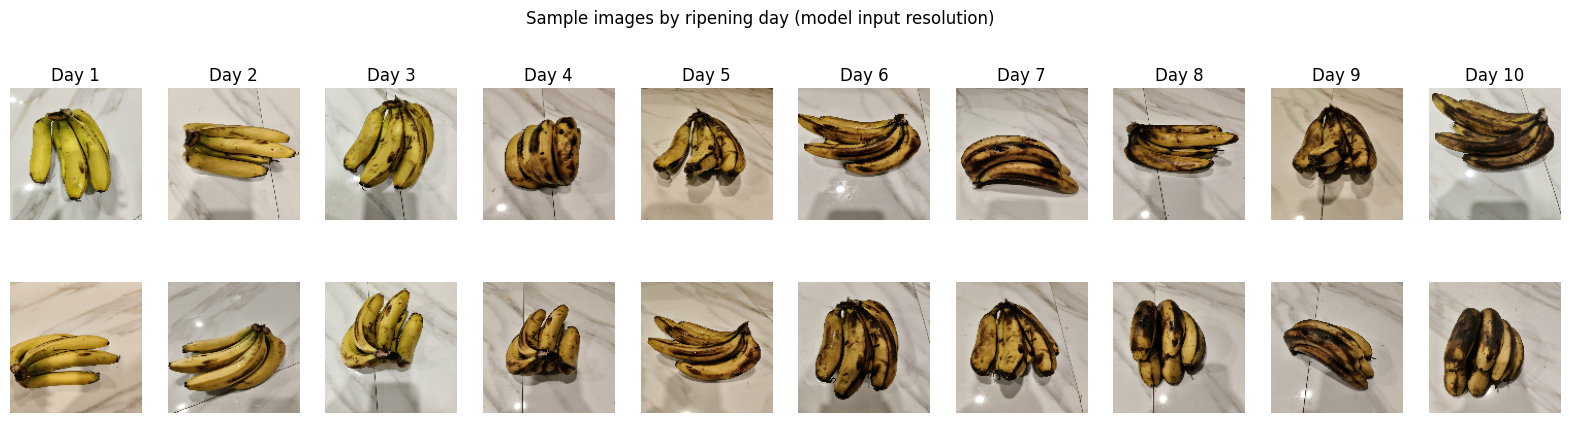

In [6]:
# A2) Sample photos: two random images per day, shown at the 128x128 resolution the models actually see
rng = np.random.default_rng(0)
fig, axs = plt.subplots(2, 10, figsize=(20, 4.6))
for j, k in enumerate(range(1, 11)):
    for i, idx in enumerate(rng.choice(np.where(days == k)[0], size=2, replace=False)):
        axs[i, j].imshow(np.clip(Xraw[idx], 0, 255).round().astype('uint8')); axs[i, j].axis('off')
        if i == 0: axs[i, j].set_title(f'Day {k}')
fig.suptitle('Sample images by ripening day (model input resolution)', y=1.02)
savefig(fig, 'eda_sample_grid.png')

,n,brightness_mean,brightness_std,saturation_mean,saturation_std,hue_mean,hue_std,dark_frac_mean,dark_frac_std
day,,,,,,,,,
1,38,0.717,0.022,0.281,0.077,0.109,0.019,0.044,0.021
2,113,0.679,0.043,0.279,0.063,0.112,0.017,0.070,0.031
3,60,0.709,0.030,0.255,0.048,0.112,0.019,0.067,0.019
4,87,0.651,0.043,0.309,0.058,0.105,0.014,0.115,0.035
5,52,0.638,0.029,0.324,0.052,0.110,0.017,0.135,0.029
6,43,0.641,0.034,0.309,0.048,0.107,0.018,0.137,0.029
7,34,0.621,0.027,0.307,0.049,0.108,0.018,0.165,0.033
8,50,0.609,0.033,0.303,0.063,0.106,0.018,0.178,0.041
9,49,0.617,0.025,0.284,0.056,0.106,0.018,0.173,0.042


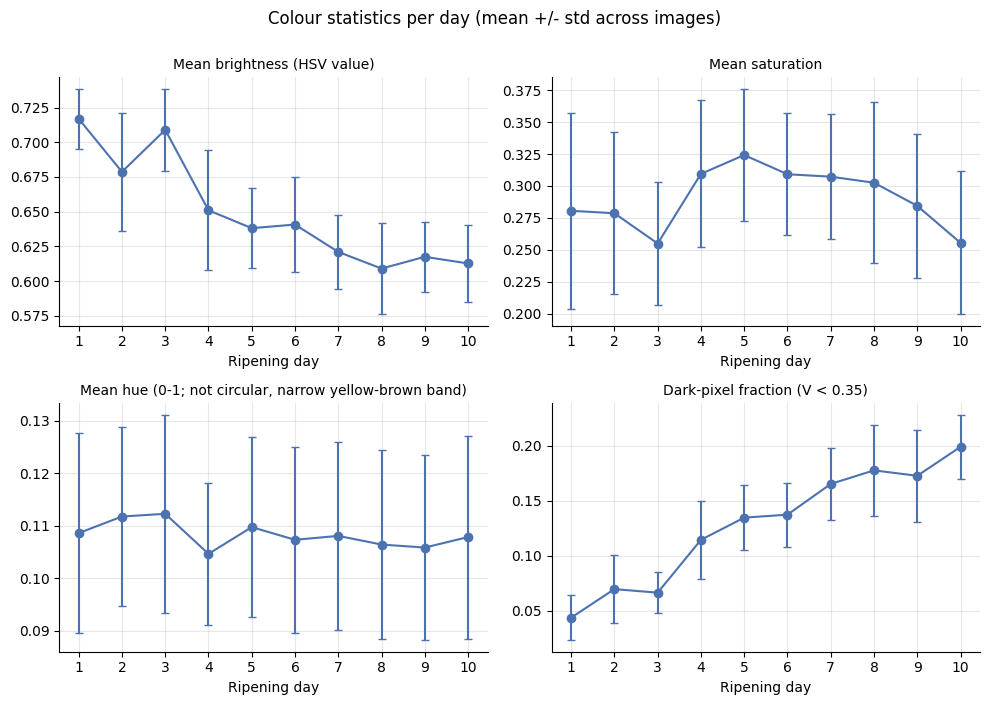

,feature,spearman_with_day,spearman_brightness_vs_dark_frac
0,brightness,-0.673,-0.871
1,saturation,0.057,-0.871
2,hue,-0.129,-0.871
3,dark_frac,0.840,-0.871


In [7]:
# A3) Colour statistics per day (HSV). dark_frac = share of pixels with V < 0.35, a crude proxy for spots / blackening
# (whole frame, so it also counts shadow and background; read it together with the sample grid).
from matplotlib.colors import rgb_to_hsv
hsv = rgb_to_hsv(Xraw / 255.0)
feat = pd.DataFrame({'day': days, 'brightness': hsv[..., 2].mean((1, 2)), 'saturation': hsv[..., 1].mean((1, 2)),
                     'hue': hsv[..., 0].mean((1, 2)), 'dark_frac': (hsv[..., 2] < 0.35).mean((1, 2))})
del hsv
g = feat.groupby('day').agg(['mean', 'std']); g.columns = [f'{a}_{b}' for a, b in g.columns]
g.insert(0, 'n', feat.groupby('day').size()); g.reset_index().to_csv(os.path.join(RES, 'eda_color_stats.csv'), index=False)
display(g.round(3))
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for a, (col, ttl) in zip(axs.ravel(), [('brightness', 'Mean brightness (HSV value)'), ('saturation', 'Mean saturation'),
                                         ('hue', 'Mean hue (0-1; not circular, narrow yellow-brown band)'), ('dark_frac', 'Dark-pixel fraction (V < 0.35)')]):
    a.errorbar(g.index, g[f'{col}_mean'], yerr=g[f'{col}_std'], marker='o', capsize=3, color='#4c72b0')
    a.set_title(ttl, fontsize=10); a.set_xlabel('Ripening day'); a.set_xticks(range(1, 11))
fig.suptitle('Colour statistics per day (mean +/- std across images)', y=1.0)
fig.tight_layout(); savefig(fig, 'eda_color_stats.png')

# How well does each simple feature track the day? (Spearman rank correlation with the true day)
cors = pd.DataFrame({'feature': ['brightness', 'saturation', 'hue', 'dark_frac'],
                     'spearman_with_day': [stats.spearmanr(feat['day'], feat[c])[0] for c in ['brightness', 'saturation', 'hue', 'dark_frac']]})
cors['spearman_brightness_vs_dark_frac'] = stats.spearmanr(feat['brightness'], feat['dark_frac'])[0]
save_csv(cors, 'eda_feature_day_correlation.csv'); display(cors.round(3))
feat.assign(file=df['filepath'].map(os.path.basename).values, split=df['split'].values).to_csv(os.path.join(RES, 'eda_image_features.csv'), index=False)

# Reference check: the published Keras model
Re-evaluates `banana_publication_model.keras` on the same data. Validation must reproduce Table 5 (MAE 0.6577, RMSE 0.8878, R2 0.9033) and the predictions must equal the stored `eval/predictions.csv`. If not, the notebook stops, because the split or the model would not be the paper's.

In [8]:
# 4) Published Keras model: reproduce Table 5, then store it as the reference row
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_pre
pub = tf.keras.models.load_model(os.path.join(BASE, 'banana_publication_model.keras'))
p_pub = pub.predict(mnv2_pre(Xraw.copy()), batch_size=64, verbose=0).flatten()
rows = [dict(model=PUB, seed='published', split=s, **reg_metrics(y[m], p_pub[m])) for s, m in MASK.items()]
pub_m = pd.DataFrame(rows); display(pub_m.round(4))

v = pub_m[pub_m.split == 'val'].iloc[0]
assert abs(v.MAE - 0.6577) < 1e-3 and abs(v.RMSE - 0.8878) < 1e-3 and abs(v.R2 - 0.9033) < 1e-3, 'Validation metrics do not reproduce Table 5'
dmax = float(np.abs(p_pub - ref['pred_publication'].values).max())
print(f'Max |difference| vs eval/predictions.csv: {dmax:.2e}')
assert dmax < 1e-3, 'Predictions differ from eval/predictions.csv'
print('Table 5 reproduced; published model confirmed.')
upsert('model_comparison.csv', pub_m, PUB)
upsert('predictions_all.csv', pred_rows(PUB, 'published', p_pub), PUB)
PUB_PARAMS = int(pub.count_params())
# Provenance check: which ImageNet weight file does Keras use for a 128x128 MobileNetV2 (the name says the input size it was trained at)?
_ = tf.keras.applications.MobileNetV2(input_shape=(128, 128, 3), include_top=False, weights='imagenet')
kdir = os.path.expanduser('~/.keras/models')
print('Keras ImageNet weight files:', sorted(os.listdir(kdir)) if os.path.isdir(kdir) else 'none found')
del _

,model,seed,split,n,MAE,MSE,RMSE,R2
0,"MobileNetV2 (Keras, published)",published,train,456,0.4925,0.3804,0.6167,0.9515
1,"MobileNetV2 (Keras, published)",published,val,57,0.6577,0.7883,0.8878,0.9033
2,"MobileNetV2 (Keras, published)",published,test,58,0.7064,0.7614,0.8726,0.9010


Max |difference| vs eval/predictions.csv: 1.57e-05
Table 5 reproduced; published model confirmed.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Keras ImageNet weight files: ['mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_128_no_top.h5']


# Train the four models (identical settings, 5 seeds)
Steps per backbone: build the torchvision model with ImageNet weights, freeze it, put it in `eval()` mode (BatchNorm uses its stored statistics), take the **pooled features** (no classifier, so no built-in dropout), cache them, then train only the head for 5 seeds. Each model is saved to Drive as soon as it finishes.

In [9]:
# 5) Backbones, feature extraction, head training (resumable)
def build_backbone(name):
    if name == 'MobileNetV2': m = tvm.mobilenet_v2(weights=tvm.MobileNet_V2_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
    elif name == 'ResNet-18': m = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1); m.fc = nn.Identity()
    elif name == 'EfficientNet-B0': m = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
    elif name == 'ShuffleNetV2': m = tvm.shufflenet_v2_x1_0(weights=tvm.ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1); m.fc = nn.Identity()
    else: raise ValueError(name)
    for p in m.parameters(): p.requires_grad = False
    return m.eval()
WEIGHTS = {'MobileNetV2': 'MobileNet_V2_Weights.IMAGENET1K_V1', 'ResNet-18': 'ResNet18_Weights.IMAGENET1K_V1',
           'EfficientNet-B0': 'EfficientNet_B0_Weights.IMAGENET1K_V1', 'ShuffleNetV2': 'ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1'}

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def to_tensor(Xb): return (torch.as_tensor(Xb).permute(0, 3, 1, 2) / 255.0 - MEAN) / STD   # ImageNet normalisation (torchvision weights)

def extract(name):
    path = os.path.join(CACHE, f'features_{name}_{IMG_SIZE}.npy')
    if os.path.exists(path): return np.load(path)
    bb = build_backbone(name).to(DEVICE); out = []
    with torch.no_grad():
        for i in range(0, len(Xraw), 64): out.append(bb(to_tensor(Xraw[i:i + 64]).to(DEVICE)).cpu().numpy())
    F = np.concatenate(out).astype('float32'); np.save(path, F)
    return F

def is_done(name):
    mc_, pr_, cu_ = load_csv('model_comparison.csv'), load_csv('predictions_all.csv'), load_csv('training_curves.csv')
    if mc_ is None or pr_ is None or cu_ is None: return False
    need = {str(s) for s in SEEDS}
    return all(set(d[d.model == name]['seed']) >= need for d in (mc_, pr_, cu_))

FEATS = {}
w_tr = day_weights(days[MASK['train']])
for name in MODELS:
    t0 = time.time(); FEATS[name] = extract(name); F = FEATS[name]
    if RESUME and is_done(name):
        print(f'{name}: already complete in the CSVs, skipped'); continue
    mrows, prows, curves = [], [], []
    for seed in SEEDS:
        head, curve = train_head(F[MASK['train']], y[MASK['train']], w_tr, seed, F[MASK['val']], y[MASK['val']])
        p = predict(head, F)
        for s, m in MASK.items(): mrows.append(dict(model=name, seed=str(seed), split=s, **reg_metrics(y[m], p[m])))
        prows.append(pred_rows(name, seed, p)); curves.append(pd.DataFrame(curve).assign(model=name, seed=str(seed)))
    upsert('model_comparison.csv', pd.DataFrame(mrows), name)
    upsert('predictions_all.csv', pd.concat(prows, ignore_index=True), name)
    upsert('training_curves.csv', pd.concat(curves, ignore_index=True), name)
    r = pd.DataFrame(mrows); r = r[r.split == 'test']
    print(f'{name}: feature dim {F.shape[1]} | test MAE {r.MAE.mean():.3f} +/- {r.MAE.std(ddof=1):.3f} | {time.time() - t0:.0f}s')
display(load_csv('model_comparison.csv').query("split == 'test'").groupby('model')[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).round(3))

MobileNetV2: already complete in the CSVs, skipped
ResNet-18: already complete in the CSVs, skipped
EfficientNet-B0: already complete in the CSVs, skipped
ShuffleNetV2: already complete in the CSVs, skipped


MAE          RMSE            R2       
                                 mean    std   mean    std   mean    std
model                                                                   
EfficientNet-B0                 0.703  0.054  0.880  0.070  0.899  0.016
MobileNetV2                     0.742  0.099  0.926  0.135  0.887  0.035
MobileNetV2 (Keras, published)  0.706    NaN  0.873    NaN  0.901    NaN
ResNet-18                       0.840  0.047  1.074  0.032  0.850  0.009
ShuffleNetV2                    0.667  0.040  0.815  0.040  0.913  0.008

In [10]:
# 6) Leave-one-day-out (LODO): train on 9 days, predict the unseen day. Uses all 571 images except the held-out day,
# with day weights recomputed per fold, exactly like the evaluation notebook, for every backbone and seed.
def run_lodo(name, F):
    rows = []
    for seed in SEEDS:
        for k in range(1, 11):
            trm = days != k
            head, _ = train_head(F[trm], y[trm], day_weights(days[trm]), seed)
            p = predict(head, F[~trm])
            rows.append(dict(model=name, seed=str(seed), held_out_day=k, n=int((~trm).sum()), MAE=float(np.abs(p - k).mean()),
                             baseline_MAE=float(abs(y[trm].mean() - k)), interpolation=bool(1 < k < 10)))
    return pd.DataFrame(rows)

for name in MODELS:
    old = load_csv('lodo_comparison.csv')
    if RESUME and old is not None and (old.model == name).sum() == len(SEEDS) * 10:
        print(f'{name}: LODO already complete, skipped'); continue
    t0 = time.time(); upsert('lodo_comparison.csv', run_lodo(name, FEATS[name]), name); print(f'{name}: LODO done in {time.time() - t0:.0f}s')

# Reference row: the published Keras head, from the evaluation notebook's own LODO file (single seed 42)
rl = pd.read_csv(os.path.join(BASE, 'eval', 'lodo_results.csv'))
rl.insert(0, 'model', PUB); rl.insert(1, 'seed', '42')
upsert('lodo_comparison.csv', rl[['model', 'seed', 'held_out_day', 'n', 'MAE', 'baseline_MAE', 'interpolation']], PUB)
L = load_csv('lodo_comparison.csv')
display(L[L.interpolation].groupby(['model', 'seed'])['MAE'].mean().groupby('model').agg(['mean', 'std']).round(3).rename(columns={'mean': 'LODO MAE days 2-9'}))

MobileNetV2: LODO already complete, skipped
ResNet-18: LODO already complete, skipped
EfficientNet-B0: LODO already complete, skipped
ShuffleNetV2: LODO already complete, skipped


,LODO MAE days 2-9,std
model,,
EfficientNet-B0,0.967,0.022
MobileNetV2,1.006,0.110
"MobileNetV2 (Keras, published)",0.884,NaN
ResNet-18,1.049,0.053
ShuffleNetV2,0.864,0.028


In [11]:
# 7) Efficiency: parameters, size, MACs (hardware independent), latency (single-thread CPU = edge-like, and GPU)
# Latency is noisy on a shared Colab CPU, so a finished measurement is kept: rerun with RESUME = False to measure again.
if RESUME and load_csv('efficiency.csv') is not None and set(load_csv('efficiency.csv').model) >= set(MODELS + [PUB]):
    eff = load_csv('efficiency.csv'); print('efficiency.csv already complete, measurement skipped')
    for _n in MODELS: FEATS[_n] = extract(_n)
else:

    from torch.utils.flop_counter import FlopCounterMode
    class Full(nn.Module):
        def __init__(self, bb, d): super().__init__(); self.bb = bb; self.head = Head(d)
        def forward(self, x): return self.head(self.bb(x))

    def count_macs(m):
        with torch.no_grad(), FlopCounterMode(display=False) as fc: m(torch.randn(1, 3, IMG_SIZE, IMG_SIZE))
        return fc.get_total_flops() / 2          # FLOPs of conv + linear layers divided by 2 = MACs

    def timings(fn, n=100, warm=20, sync=False):
        for _ in range(warm): fn()
        if sync: torch.cuda.synchronize()
        ts = []
        for _ in range(n):
            t = time.perf_counter(); fn()
            if sync: torch.cuda.synchronize()
            ts.append((time.perf_counter() - t) * 1e3)
        return np.array(ts)

    ROUNDS = 3      # three interleaved rounds of 100 runs: one slow moment on the shared Colab CPU cannot decide the ranking
    n_threads = torch.get_num_threads(); torch.set_num_threads(1)
    cpu_models = {n: Full(build_backbone(n), FEATS[n].shape[1]).eval() for n in MODELS}
    x_cpu = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    cpu_t = {n: [] for n in MODELS}
    with torch.inference_mode():
        for _ in range(ROUNDS):
            for n in MODELS: cpu_t[n].append(timings(lambda: cpu_models[n](x_cpu)))
    # Published model: the fp16 TFLite file, 1 thread (a different runtime, so only roughly comparable)
    interp = tf.lite.Interpreter(model_path=os.path.join(BASE, 'eval', 'banana_publication_fp16.tflite'), num_threads=1); interp.allocate_tensors()
    inp = interp.get_input_details()[0]; xt = np.random.rand(*inp['shape']).astype(inp['dtype'])
    def tfl(): interp.set_tensor(inp['index'], xt); interp.invoke()
    tfl_t = [timings(tfl) for _ in range(ROUNDS)]
    torch.set_num_threads(n_threads)

    gpu_t = {}
    if DEVICE == 'cuda':
        x_gpu = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device='cuda')
        gm = {n: Full(build_backbone(n), FEATS[n].shape[1]).to('cuda').eval() for n in MODELS}
        with torch.inference_mode():
            for n in MODELS: gpu_t[n] = np.concatenate([timings(lambda: gm[n](x_gpu), sync=True) for _ in range(ROUNDS)])

    def q(a): a = np.concatenate(a) if isinstance(a, list) else a; return float(np.median(a)), float(np.percentile(a, 25)), float(np.percentile(a, 75))
    erows = []
    for n in MODELS:
        params = sum(p.numel() for p in cpu_models[n].parameters()); c = q(cpu_t[n]); gq = q(gpu_t[n]) if n in gpu_t else (np.nan,) * 3
        erows.append(dict(model=n, runtime='PyTorch fp32, 1 CPU thread / GPU batch 1', weights=WEIGHTS[n], feature_dim=FEATS[n].shape[1], params=params,
                          size_fp32_MB=params * 4 / 1e6, tflite_fp16_MB=np.nan, MACs_M=count_macs(cpu_models[n]) / 1e6,
                          cpu_ms_median=c[0], cpu_ms_p25=c[1], cpu_ms_p75=c[2], gpu_ms_median=gq[0], gpu_ms_p25=gq[1], gpu_ms_p75=gq[2],
                          cpu_name=CPU_NAME, gpu_name=GPU_NAME))
    c = q(tfl_t)
    erows.append(dict(model=PUB, runtime='TFLite fp16, 1 CPU thread (different runtime)', weights='Keras MobileNetV2 ImageNet 128', feature_dim=1280, params=PUB_PARAMS,
                      size_fp32_MB=PUB_PARAMS * 4 / 1e6, tflite_fp16_MB=os.path.getsize(os.path.join(BASE, 'eval', 'banana_publication_fp16.tflite')) / 1e6,
                      MACs_M=np.nan, cpu_ms_median=c[0], cpu_ms_p25=c[1], cpu_ms_p75=c[2], gpu_ms_median=np.nan, gpu_ms_p25=np.nan, gpu_ms_p75=np.nan,
                      cpu_name=CPU_NAME, gpu_name=GPU_NAME))
    eff = pd.DataFrame(erows); save_csv(eff, 'efficiency.csv')
    display(eff[['model', 'params', 'size_fp32_MB', 'tflite_fp16_MB', 'MACs_M', 'cpu_ms_median', 'gpu_ms_median']].round(3))
    del cpu_models

efficiency.csv already complete, measurement skipped


# Part B. Error analysis, one section per model (test set)
Each section shows: (a) predicted vs actual with the ideal line, (b) MAE per day (mean +/- std over the 5 seeds, n = test images per day), (c) residuals vs true day, (d) training and validation loss curves (mean over seeds, band = min to max), and a second figure with the 5 worst-predicted test images.

**Best seed** is chosen by *validation* MAE, never by test, so the test set stays untouched by any selection. The per-day numbers rest on only 3-12 test images each, so single bars are noisy; read the pattern, not one bar.

In [12]:
# B0) Per-day errors for every model and seed (val and test), saved once for all sections and Part C
pr_all = load_csv('predictions_all.csv')
pr_all = pr_all[pr_all.split.isin(['val', 'test'])].assign(ae=lambda d: (d.pred - d.day).abs())
pde = pr_all.groupby(['model', 'seed', 'split', 'day']).agg(n=('ae', 'size'), MAE=('ae', 'mean')).reset_index()
save_csv(pde, 'per_day_errors.csv'); print(len(pde), 'rows saved to per_day_errors.csv')

def error_analysis(name):
    mc_, pr_, cu_ = load_csv('model_comparison.csv'), load_csv('predictions_all.csv'), load_csv('training_curves.csv')
    val = mc_[(mc_.model == name) & (mc_.split == 'val')].set_index('seed')['MAE']; best = str(val.idxmin())
    T = pr_[(pr_.model == name) & (pr_.split == 'test')]; Bt = T[T.seed == best].sort_values('row'); col = COLORS[name]
    rng = np.random.default_rng(0); jit = rng.uniform(-.12, .12, len(Bt))
    fig, ax = plt.subplots(2, 2, figsize=(11, 9))
    a = ax[0, 0]
    a.scatter(Bt.day + jit, Bt.pred, s=30, alpha=.85, color=col, edgecolor='k', lw=.4); a.plot([0, 11], [0, 11], 'r--', lw=1.5, label='ideal (y = x)')
    a.set(xlim=(0, 11), ylim=(0, 11), xlabel='Actual day', ylabel='Predicted day', title=f'(a) Test: predicted vs actual\nbest seed {best}, MAE {np.abs(Bt.pred - Bt.day).mean():.3f}'); a.legend()
    T2 = T.assign(ae=(T.pred - T.day).abs()); ps = T2.groupby(['seed', 'day'])['ae'].mean().unstack('day'); nday = T2[T2.seed == best].groupby('day').size()
    b = ax[0, 1]; b.bar(ps.columns, ps.mean(), yerr=ps.std(ddof=1), capsize=3, color=col, alpha=.85)
    b.set_xticks(range(1, 11)); b.set_xticklabels([f'{d}\n(n={nday.get(d, 0)})' for d in range(1, 11)], fontsize=8)
    b.set(xlabel='Actual day (test images)', ylabel='MAE (days)', title='(b) Test MAE per day, mean +/- std over 5 seeds')
    c_ = ax[1, 0]; res = Bt.pred - Bt.day
    c_.scatter(Bt.day + jit, res, s=30, alpha=.85, color=col, edgecolor='k', lw=.4); c_.axhline(0, color='r', ls='--', lw=1.5)
    c_.plot(sorted(Bt.day.unique()), res.groupby(Bt.day).mean().sort_index().values, 'k-o', ms=4, lw=1, label='mean residual per day'); c_.legend()
    c_.set(xlabel='Actual day', ylabel='Residual = predicted - actual (days)', title='(c) Test residuals vs true day'); c_.set_xticks(range(1, 11))
    cm = cu_[cu_.model == name].groupby('epoch')[['train_loss', 'val_loss']].agg(['mean', 'min', 'max']); d_ = ax[1, 1]
    for k_, lab, cc in [('train_loss', 'train (weighted MSE, dropout on)', col), ('val_loss', 'validation MSE', 'k')]:
        d_.plot(cm.index, cm[k_]['mean'], color=cc, label=lab); d_.fill_between(cm.index, cm[k_]['min'], cm[k_]['max'], color=cc, alpha=.15)
    d_.set(xlabel='Epoch', ylabel='MSE (days^2)', title='(d) Loss curves (mean over seeds, band = min-max)'); d_.legend()
    fig.suptitle(f'{name}: test-set error analysis', fontsize=13, y=1.0); fig.tight_layout(); savefig(fig, f'{SLUG[name]}_diagnostics.png')
    w = Bt.assign(ae=(Bt.pred - Bt.day).abs()).nlargest(5, 'ae')
    fig, axs = plt.subplots(1, 5, figsize=(15, 3.6))
    for a, (_, r) in zip(axs, w.iterrows()):
        a.imshow(np.clip(Xraw[int(r.row)], 0, 255).round().astype('uint8')); a.axis('off'); a.set_title(f'true {int(r.day)} | pred {r.pred:.1f}\n|error| {r.ae:.2f} days', fontsize=9)
    fig.suptitle(f'{name}: 5 worst-predicted test images (seed {best})', y=1.04); savefig(fig, f'{SLUG[name]}_worst5.png')
    t = mc_[(mc_.model == name) & (mc_.split == 'test')]
    print(f"{name} | test MAE {t.MAE.mean():.3f} +/- {t.MAE.std(ddof=1):.3f} | RMSE {t.RMSE.mean():.3f} +/- {t.RMSE.std(ddof=1):.3f} | R2 {t.R2.mean():.3f} +/- {t.R2.std(ddof=1):.3f} | best seed (by val MAE) = {best}")

420 rows saved to per_day_errors.csv


## B1. MobileNetV2

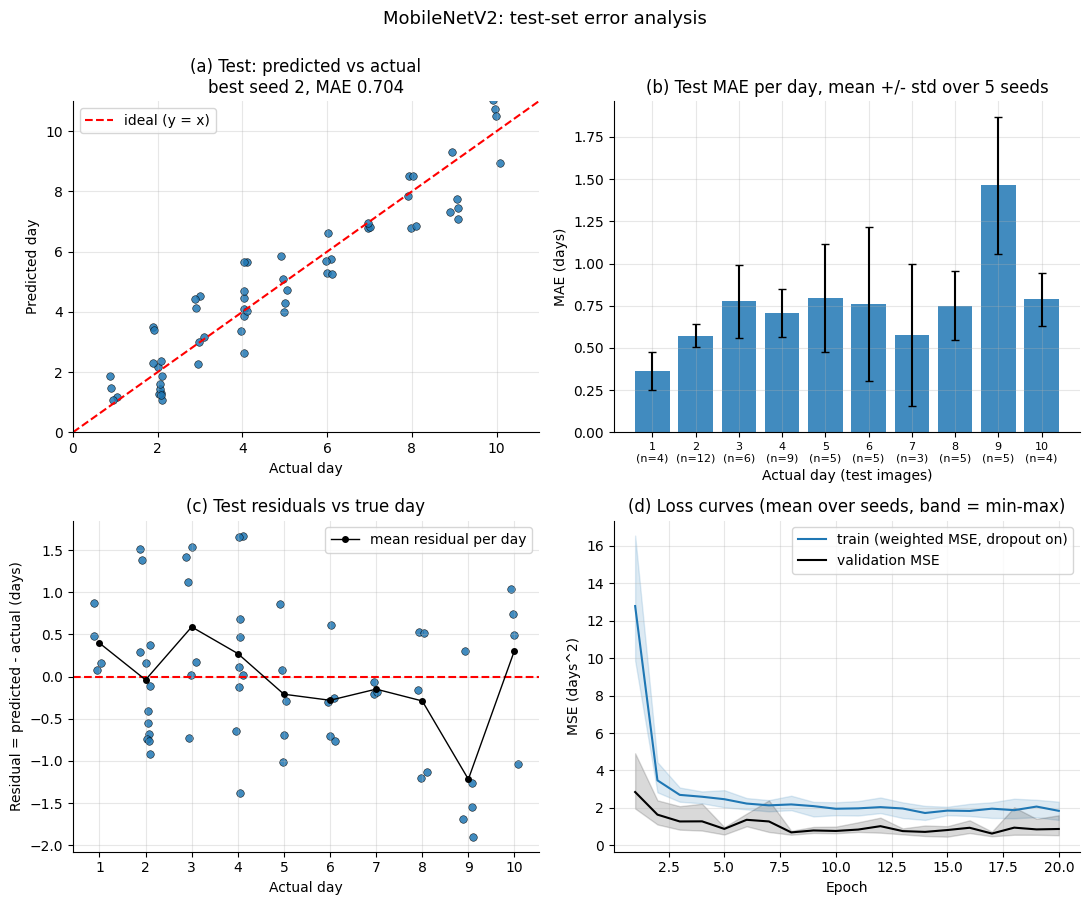

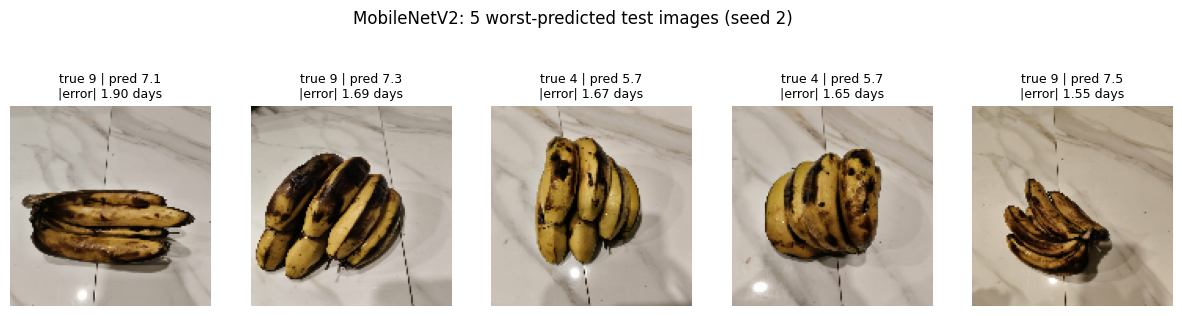

MobileNetV2 | test MAE 0.742 +/- 0.099 | RMSE 0.926 +/- 0.135 | R2 0.887 +/- 0.035 | best seed (by val MAE) = 2


In [13]:
error_analysis('MobileNetV2')

## B2. ResNet-18

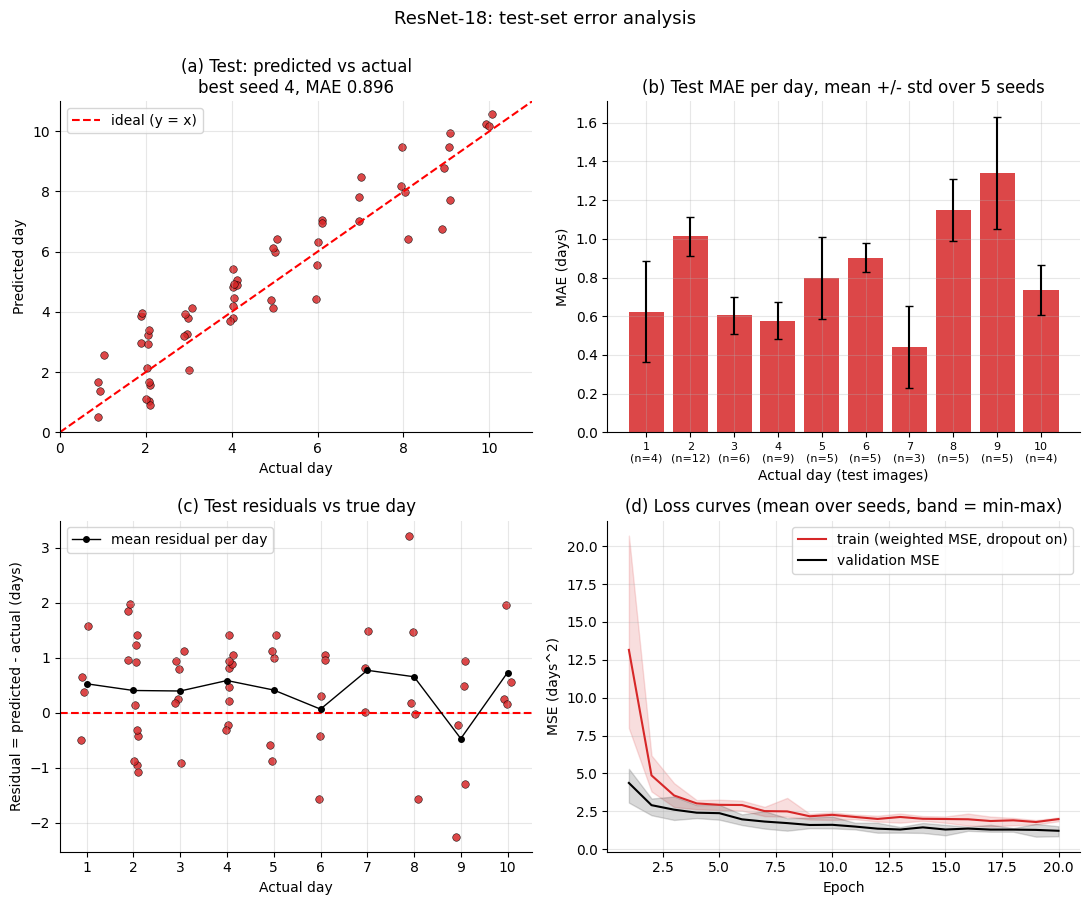

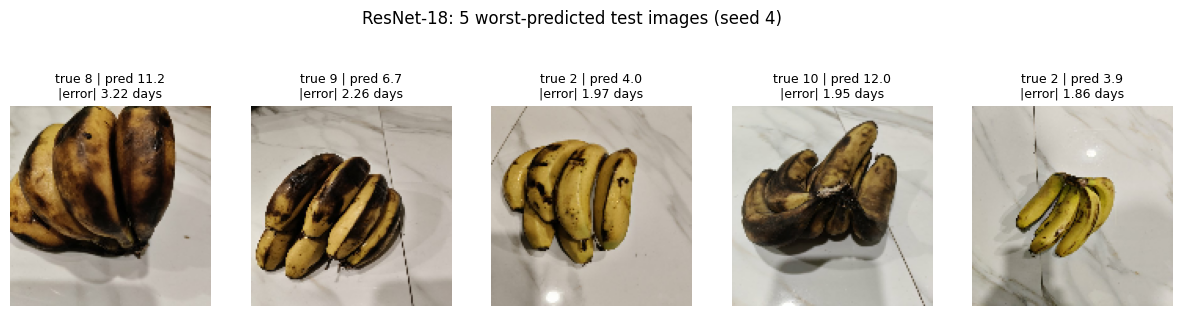

ResNet-18 | test MAE 0.840 +/- 0.047 | RMSE 1.074 +/- 0.032 | R2 0.850 +/- 0.009 | best seed (by val MAE) = 4


In [14]:
error_analysis('ResNet-18')

## B3. EfficientNet-B0

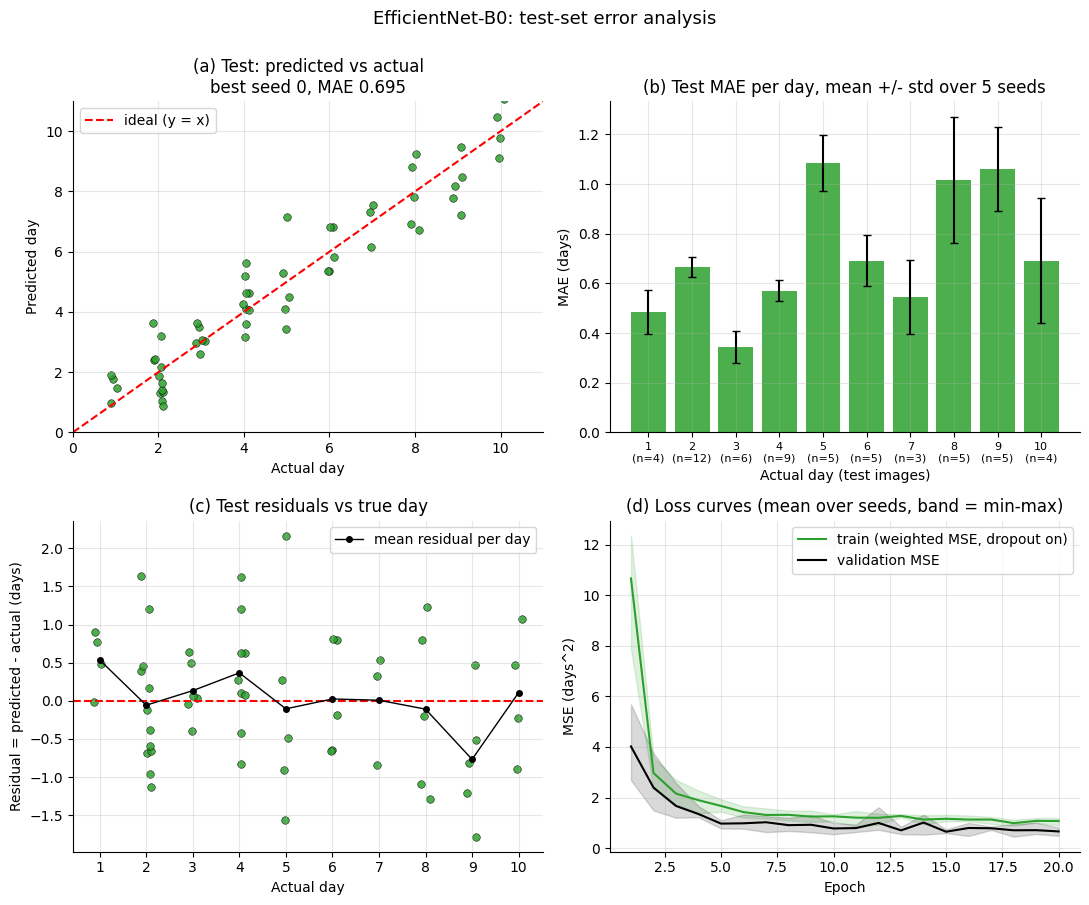

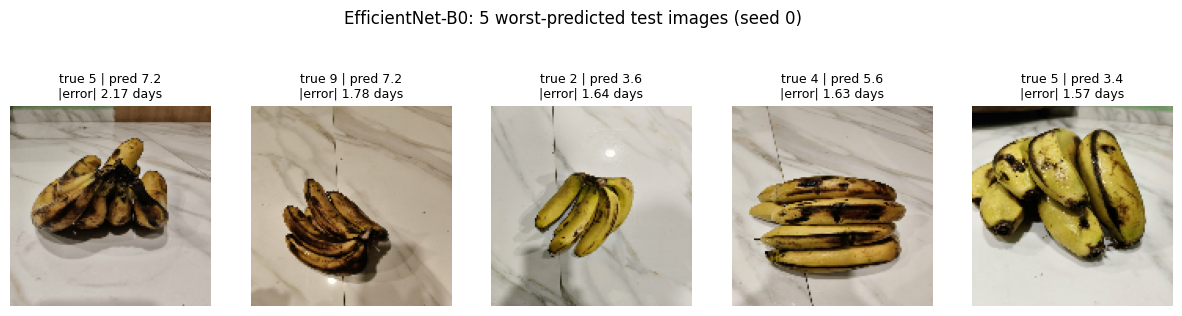

EfficientNet-B0 | test MAE 0.703 +/- 0.054 | RMSE 0.880 +/- 0.070 | R2 0.899 +/- 0.016 | best seed (by val MAE) = 0


In [15]:
error_analysis('EfficientNet-B0')

## B4. ShuffleNetV2

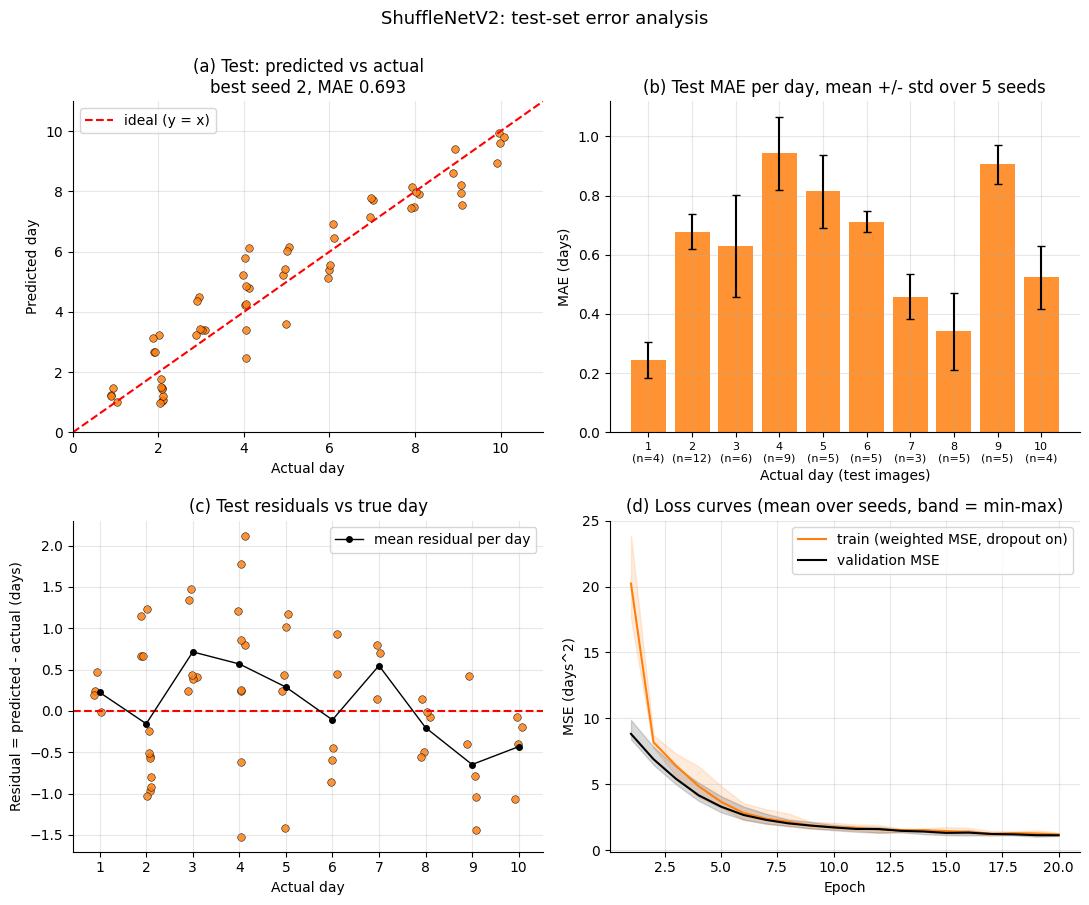

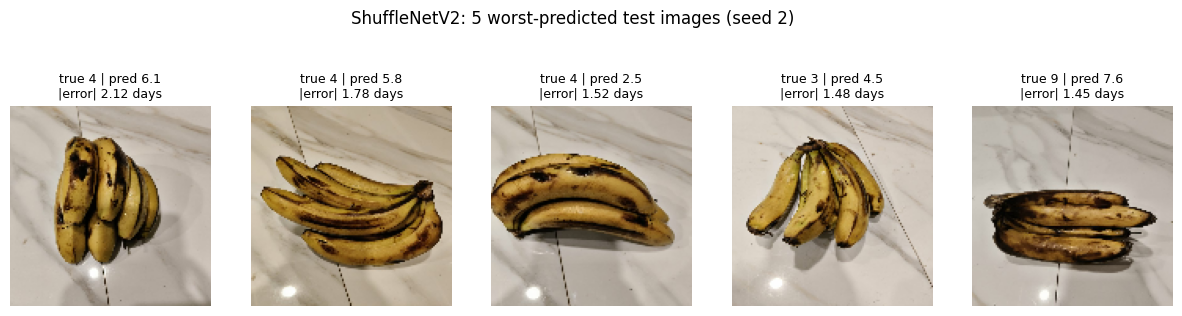

ShuffleNetV2 | test MAE 0.667 +/- 0.040 | RMSE 0.815 +/- 0.040 | R2 0.913 +/- 0.008 | best seed (by val MAE) = 2


In [16]:
error_analysis('ShuffleNetV2')

# Part C. Final comparison of all four models
One table (accuracy and efficiency together, published model as a reference row, best of the four in bold) and two figures. Uncertainty: seeds change only the head's initialisation and batch order, but the head keeps its epoch-20 weights, so the seed spread (the +/- in the table) is not negligible. With only 58 test images the sampling uncertainty is larger still, so the table also gives a **bootstrap 95% CI** for test MAE (resampling the 58 test images) and a **paired comparison with MobileNetV2** (same images, per-image error difference). **Bold marks the best mean in a column; it does not mean the difference is statistically significant.**

In [17]:
# C1) Uncertainty on test MAE (bootstrap over the 58 test images) and paired comparison with MobileNetV2
pr_ = load_csv('predictions_all.csv'); te = pr_[pr_.split == 'test'].assign(ae=lambda d: (d.pred - d.day).abs())
E = {n: te[te.model == n].groupby('row')['ae'].mean().sort_index() for n in MODELS + [PUB]}     # per-image error, averaged over seeds
assert all(len(e) == 58 for e in E.values())
rng = np.random.default_rng(0); NB = 10000; IDX = rng.integers(0, 58, size=(NB, 58))
srows = []
for n in MODELS + [PUB]:
    e = E[n].values; d = e - E['MobileNetV2'].values; bm = e[IDX].mean(1); bd = d[IDX].mean(1)
    try: pw = float(stats.wilcoxon(d).pvalue)
    except ValueError: pw = np.nan       # all differences zero (MobileNetV2 vs itself)
    srows.append(dict(model=n, test_MAE=float(e.mean()), MAE_ci_lo=float(np.percentile(bm, 2.5)), MAE_ci_hi=float(np.percentile(bm, 97.5)),
                      reference='MobileNetV2' if n != 'MobileNetV2' else '', delta_vs_MNV2=float(d.mean()) if n != 'MobileNetV2' else np.nan,
                      delta_ci_lo=float(np.percentile(bd, 2.5)) if n != 'MobileNetV2' else np.nan, delta_ci_hi=float(np.percentile(bd, 97.5)) if n != 'MobileNetV2' else np.nan,
                      wilcoxon_p=pw if n != 'MobileNetV2' else np.nan, n_images=58, bootstrap_reps=NB))
sig = pd.DataFrame(srows); save_csv(sig, 'significance.csv'); display(sig.round(4))

/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


,model,test_MAE,MAE_ci_lo,MAE_ci_hi,reference,delta_vs_MNV2,delta_ci_lo,delta_ci_hi,wilcoxon_p,n_images,bootstrap_reps
0,MobileNetV2,0.7425,0.6353,0.8576,,NaN,NaN,NaN,NaN,58,10000
1,ResNet-18,0.8395,0.7015,0.9917,MobileNetV2,0.0970,-0.0527,0.2530,0.3671,58,10000
2,EfficientNet-B0,0.7032,0.5901,0.8249,MobileNetV2,-0.0393,-0.1842,0.1055,0.6340,58,10000
3,ShuffleNetV2,0.6671,0.5551,0.7817,MobileNetV2,-0.0754,-0.2020,0.0518,0.1947,58,10000
4,"MobileNetV2 (Keras, published)",0.7064,0.5798,0.8421,MobileNetV2,-0.0361,-0.1724,0.1020,0.4096,58,10000


In [18]:
# C2) Final comparison table (CSV with raw numbers, Markdown for the paper)
mc_ = load_csv('model_comparison.csv'); L = load_csv('lodo_comparison.csv'); eff = load_csv('efficiency.csv').set_index('model'); sig_ = load_csv('significance.csv').set_index('model')
rows = []
for n in [PUB] + MODELS:
    r = {'model': n}
    for sp in ['test', 'val']:
        s_ = mc_[(mc_.model == n) & (mc_.split == sp)]
        for k in ['MAE', 'RMSE', 'R2']:
            r[f'{sp}_{k}_mean'] = s_[k].mean(); r[f'{sp}_{k}_std'] = s_[k].std(ddof=1) if len(s_) > 1 else np.nan
    for k in ['MAE_ci_lo', 'MAE_ci_hi', 'delta_vs_MNV2', 'delta_ci_lo', 'delta_ci_hi', 'wilcoxon_p']: r['test_' + k if k.startswith('MAE') else k] = sig_.loc[n, k]
    ps = L[(L.model == n) & (L.interpolation)].groupby('seed')['MAE'].mean()
    r['lodo_MAE_d2_9_mean'] = ps.mean(); r['lodo_MAE_d2_9_std'] = ps.std(ddof=1) if len(ps) > 1 else np.nan
    for k in ['params', 'size_fp32_MB', 'MACs_M', 'cpu_ms_median', 'gpu_ms_median', 'tflite_fp16_MB']: r[k] = eff.loc[n, k]
    r['latency_runtime'] = eff.loc[n, 'runtime']
    rows.append(r)
fin = pd.DataFrame(rows); save_csv(fin, 'final_comparison_table.csv')

def f(m, s=None, d=3):
    if pd.isna(m): return 'n/a'
    return f'{m:.{d}f}' if (s is None or pd.isna(s)) else f'{m:.{d}f} ± {s:.{d}f}'
def fdelta(r):
    if r.model == 'MobileNetV2': return 'reference'
    return f'{r.delta_vs_MNV2:+.3f} [{r.delta_ci_lo:+.3f}, {r.delta_ci_hi:+.3f}], p = {r.wilcoxon_p:.2f}'
def fcpu(r):       # the published row was timed as TFLite fp16, a different runtime, so it is kept out of this column
    return 'n/a*' if r.model == PUB else f(r.cpu_ms_median, None, 2)
COLS = [('Test MAE ↓', lambda r: f(r.test_MAE_mean, r.test_MAE_std), 'test_MAE_mean', 'min'),
        ('Test MAE 95% CI', lambda r: f'[{r.test_MAE_ci_lo:.3f}, {r.test_MAE_ci_hi:.3f}]', None, None),
        ('Δ test MAE vs MobileNetV2 [95% CI], Wilcoxon p', fdelta, None, None),
        ('Test RMSE ↓', lambda r: f(r.test_RMSE_mean, r.test_RMSE_std), 'test_RMSE_mean', 'min'),
        ('Test R² ↑', lambda r: f(r.test_R2_mean, r.test_R2_std), 'test_R2_mean', 'max'),
        ('Val MAE ↓', lambda r: f(r.val_MAE_mean, r.val_MAE_std), 'val_MAE_mean', 'min'),
        ('Val RMSE ↓', lambda r: f(r.val_RMSE_mean, r.val_RMSE_std), 'val_RMSE_mean', 'min'),
        ('Val R² ↑', lambda r: f(r.val_R2_mean, r.val_R2_std), 'val_R2_mean', 'max'),
        ('LODO MAE d2-9 ↓', lambda r: f(r.lodo_MAE_d2_9_mean, r.lodo_MAE_d2_9_std), 'lodo_MAE_d2_9_mean', 'min'),
        ('Params (M) ↓', lambda r: f(r.params / 1e6, None, 2), 'params', 'min'),
        ('Size fp32 (MB) ↓', lambda r: f(r.size_fp32_MB, None, 2), 'size_fp32_MB', 'min'),
        ('MACs (M) ↓', lambda r: f(r.MACs_M, None, 1), 'MACs_M', 'min'),
        ('CPU ms ↓', fcpu, 'cpu_ms_median', 'min'),
        ('GPU ms ↓', lambda r: f(r.gpu_ms_median, None, 2), 'gpu_ms_median', 'min')]
four = fin[fin.model.isin(MODELS)]; best = {}
for h, fm, key, how in COLS:
    if key: v = four[key].dropna(); best[key] = (v.min() if how == 'min' else v.max()) if len(v) else None
lines = ['| Model | ' + ' | '.join(h for h, *_ in COLS) + ' |', '|' + '---|' * (len(COLS) + 1)]
for _, r in fin.iterrows():
    cells = []
    for h, fm, key, how in COLS:
        s = fm(r)
        if key and r.model in MODELS and best.get(key) is not None and np.isclose(r[key], best[key]): s = f'**{s}**'
        cells.append(s)
    lines.append(f'| {r.model} | ' + ' | '.join(cells) + ' |')
pub_r = fin[fin.model == PUB].iloc[0]
notes = ['', 'Notes: ± is the standard deviation over 5 seeds (the published row is one trained model, so no ±). **Bold marks the best mean among the four models in a column; it does not mean the difference is statistically significant** (see the Δ column: paired difference to MobileNetV2 over the same 58 test images, bootstrap 95% CI, Wilcoxon signed-rank p). The published row is a reference and is not ranked.',
         'Test = 58 images, Val = 57 images (Table 5 of the paper used Val). The CI is a bootstrap over the 58 test images (10,000 resamples) for the seed-averaged MAE.',
         'LODO = leave-one-day-out MAE averaged over days 2-9 (the published row: one seed). Size = parameters x 4 bytes. MACs = conv + linear layers at 128x128.',
         'CPU = median single-thread latency, batch 1, PyTorch fp32. GPU = median batch-1 latency on the Colab GPU.',
         f'* Published model, TFLite fp16: {pub_r.tflite_fp16_MB:.2f} MB file, {pub_r.cpu_ms_median:.2f} ms median CPU latency (1 thread). Different runtime, so not comparable with the PyTorch column and not shown in it.']
md_text = '\n'.join(lines + notes); open(os.path.join(RES, 'final_comparison_table.md'), 'w').write(md_text); display(Markdown(md_text))

| Model | Test MAE ↓ | Test MAE 95% CI | Δ test MAE vs MobileNetV2 [95% CI], Wilcoxon p | Test RMSE ↓ | Test R² ↑ | Val MAE ↓ | Val RMSE ↓ | Val R² ↑ | LODO MAE d2-9 ↓ | Params (M) ↓ | Size fp32 (MB) ↓ | MACs (M) ↓ | CPU ms ↓ | GPU ms ↓ |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| MobileNetV2 (Keras, published) | 0.706 | [0.580, 0.842] | -0.036 [-0.172, +0.102], p = 0.41 | 0.873 | 0.901 | 0.658 | 0.888 | 0.903 | 0.884 | 2.34 | 9.36 | n/a | n/a* | n/a |
| MobileNetV2 | 0.742 ± 0.099 | [0.635, 0.858] | reference | 0.926 ± 0.135 | 0.887 ± 0.035 | 0.738 ± 0.161 | 0.915 ± 0.206 | 0.893 ± 0.052 | 1.006 ± 0.110 | 2.31 | 9.22 | 97.9 | 11.78 | 5.33 |
| ResNet-18 | 0.840 ± 0.047 | [0.701, 0.992] | +0.097 [-0.053, +0.253], p = 0.37 | 1.074 ± 0.032 | 0.850 ± 0.009 | 0.861 ± 0.103 | 1.093 ± 0.117 | 0.852 ± 0.031 | 1.049 ± 0.053 | 11.21 | 44.84 | 592.2 | 23.52 | **2.80** |
| EfficientNet-B0 | 0.703 ± 0.054 | [0.590, 0.825] | -0.039 [-0.184, +0.105], p = 0.63 | 0.880 ± 0.070 | 0.899 ± 0.016 | **0.640 ± 0.053** | **0.809 ± 0.074** | **0.919 ± 0.014** | 0.967 ± 0.022 | 4.09 | 16.36 | 126.1 | 17.77 | 8.69 |
| ShuffleNetV2 | **0.667 ± 0.040** | [0.555, 0.782] | -0.075 [-0.202, +0.052], p = 0.19 | **0.815 ± 0.040** | **0.913 ± 0.008** | 0.795 ± 0.019 | 1.070 ± 0.022 | 0.860 ± 0.006 | **0.864 ± 0.028** | **1.32** | **5.28** | **47.0** | **10.87** | 6.38 |

Notes: ± is the standard deviation over 5 seeds (the published row is one trained model, so no ±). **Bold marks the best mean among the four models in a column; it does not mean the difference is statistically significant** (see the Δ column: paired difference to MobileNetV2 over the same 58 test images, bootstrap 95% CI, Wilcoxon signed-rank p). The published row is a reference and is not ranked.
Test = 58 images, Val = 57 images (Table 5 of the paper used Val). The CI is a bootstrap over the 58 test images (10,000 resamples) for the seed-averaged MAE.
LODO = leave-one-day-out MAE averaged over days 2-9 (the published row: one seed). Size = parameters x 4 bytes. MACs = conv + linear layers at 128x128.
CPU = median single-thread latency, batch 1, PyTorch fp32. GPU = median batch-1 latency on the Colab GPU.
* Published model, TFLite fp16: 4.63 MB file, 4.40 ms median CPU latency (1 thread). Different runtime, so not comparable with the PyTorch column and not shown in it.

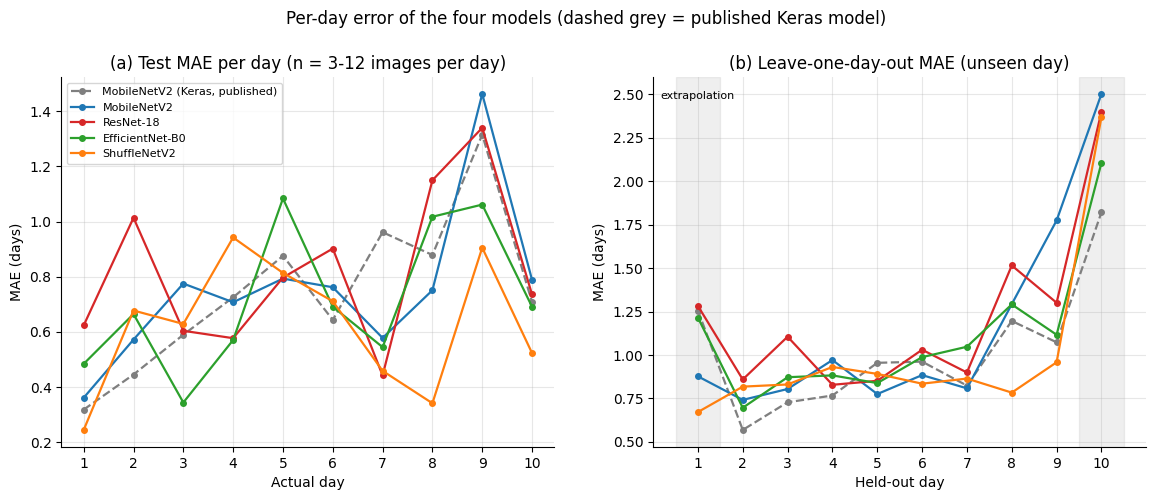

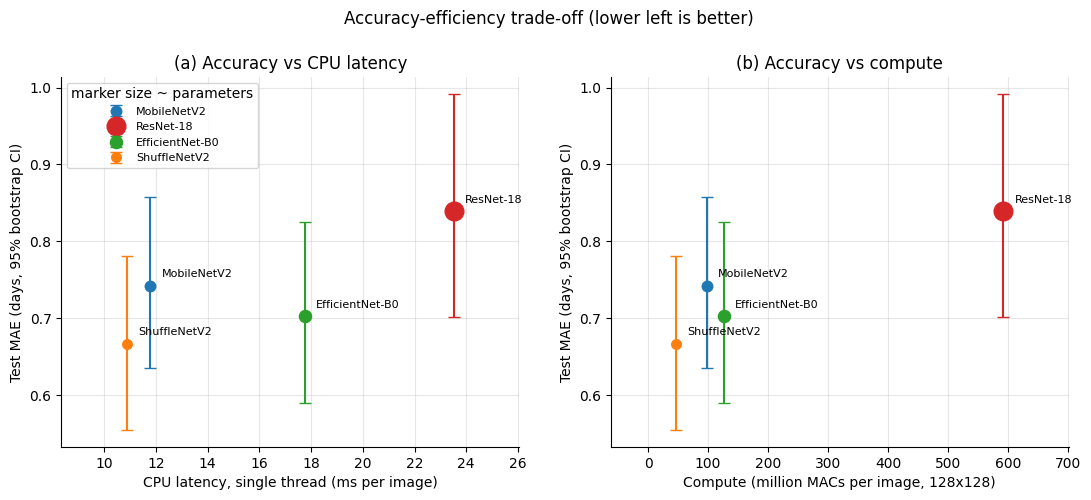

In [19]:
# C3) Two comparison figures
pde = load_csv('per_day_errors.csv'); L = load_csv('lodo_comparison.csv'); eff = load_csv('efficiency.csv').set_index('model'); sig_ = load_csv('significance.csv').set_index('model')
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for n in [PUB] + MODELS:
    ls = '--' if n == PUB else '-'; kw = dict(color=COLORS[n], ls=ls, marker='o', ms=4, lw=1.6, label=n)
    t = pde[(pde.model == n) & (pde.split == 'test')].groupby(['seed', 'day'])['MAE'].mean().groupby('day').mean(); axs[0].plot(t.index, t.values, **kw)
    l = L[L.model == n].groupby(['seed', 'held_out_day'])['MAE'].mean().groupby('held_out_day').mean(); axs[1].plot(l.index, l.values, **kw)
axs[0].set(title='(a) Test MAE per day (n = 3-12 images per day)', xlabel='Actual day', ylabel='MAE (days)'); axs[1].set(title='(b) Leave-one-day-out MAE (unseen day)', xlabel='Held-out day', ylabel='MAE (days)')
axs[1].axvspan(.5, 1.5, color='gray', alpha=.12); axs[1].axvspan(9.5, 10.5, color='gray', alpha=.12); axs[1].text(1, axs[1].get_ylim()[1] * .97, 'extrapolation', ha='center', va='top', fontsize=8)
for a in axs: a.set_xticks(range(1, 11))
axs[0].legend(fontsize=8); fig.suptitle('Per-day error of the four models (dashed grey = published Keras model)', y=1.02); savefig(fig, 'comparison_per_day_mae.png')

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for a, (xcol, xl) in zip(axs, [('cpu_ms_median', 'CPU latency, single thread (ms per image)'), ('MACs_M', 'Compute (million MACs per image, 128x128)')]):
    for n in MODELS:
        m_ = sig_.loc[n, 'test_MAE']; lo, hi = sig_.loc[n, 'MAE_ci_lo'], sig_.loc[n, 'MAE_ci_hi']
        a.errorbar(eff.loc[n, xcol], m_, yerr=[[m_ - lo], [hi - m_]], fmt='o', ms=6 + eff.loc[n, 'params'] / 1.5e6, color=COLORS[n], capsize=4, label=n)
        a.annotate(n, (eff.loc[n, xcol], m_), textcoords='offset points', xytext=(8, 6), fontsize=8)
    a.set(xlabel=xl, ylabel='Test MAE (days, 95% bootstrap CI)')
    a.margins(x=0.2)
axs[0].set_title('(a) Accuracy vs CPU latency'); axs[1].set_title('(b) Accuracy vs compute'); axs[0].legend(fontsize=8, title='marker size ~ parameters')
fig.suptitle('Accuracy-efficiency trade-off (lower left is better)', y=1.02); savefig(fig, 'comparison_accuracy_vs_latency.png')

In [20]:
# 8) Done: list everything written to Drive
for root, _, files in os.walk(RES):
    for fn in sorted(files): print(os.path.join(root, fn).replace(RES, 'results'), round(os.path.getsize(os.path.join(root, fn)) / 1e3, 1), 'kB')
print('\nALL DONE')

results/eda_color_stats.csv 1.2 kB
results/eda_feature_day_correlation.csv 0.3 kB
results/eda_image_features.csv 45.2 kB
results/eda_images_per_day.csv 0.1 kB
results/efficiency.csv 1.5 kB
results/final_comparison_table.csv 2.7 kB
results/final_comparison_table.md 2.4 kB
results/lodo_comparison.csv 13.1 kB
results/model_comparison.csv 6.3 kB
results/per_day_errors.csv 18.4 kB
results/predictions_all.csv 826.8 kB
results/run_info.json 0.4 kB
results/significance.csv 0.9 kB
results/training_curves.csv 21.8 kB
results/figures/comparison_accuracy_vs_latency.png 224.6 kB
results/figures/comparison_per_day_mae.png 519.1 kB
results/figures/eda_color_stats.png 311.8 kB
results/figures/eda_images_per_day.png 87.7 kB
results/figures/eda_sample_grid.png 854.5 kB
results/figures/efficientnetb0_diagnostics.png 573.0 kB
results/figures/efficientnetb0_worst5.png 292.8 kB
results/figures/mobilenetv2_diagnostics.png 585.7 kB
results/figures/mobilenetv2_worst5.png 283.1 kB
results/figures/resnet18_diagn